# 02 · Same track, two kinds of machine

How much faster is a Formula 1 car than a MotoGP bike around the same circuit, and where is the
gap biggest?

**Method**

* Compare **pole laps**: the fastest lap each series sets with low fuel, new tyres and full
  attack, which is the closest like-for-like.
* **Wet sessions are excluded.** A pole more than 3 % slower than the same race's fastest lap,
  or more than 10 % off the usual pole for that layout, is treated as wet.
* **Layouts are checked from the data.** Lap length = speed × lap time for each series
  (Jolpica's fastest-lap speed for F1, the race fastest-lap record for MotoGP). Lap-time
  *ratios* are only shown where both series ran the same length within 0.25 % (about 13 m).
  Speed comparisons are valid either way.

In [1]:
import matplotlib.pyplot as plt

from f1_vs_motogp import plots
from f1_vs_motogp.analysis import race_summaries, venue_comparison
from f1_vs_motogp.config import DATA_PROCESSED
from f1_vs_motogp.data import load_tables

plots.apply_style()
summary = race_summaries(load_tables())
summary.to_parquet(DATA_PROCESSED / "race_summary.parquet", index=False)
vc = venue_comparison(summary)
vc.to_parquet(DATA_PROCESSED / "venue_comparison.parquet", index=False)
print(f"{len(vc)} F1/MotoGP pairs across {vc['venue'].nunique()} venues "
      f"({(~vc['same_year']).sum()} paired with the adjacent season)")

59 F1/MotoGP pairs across 8 venues (7 paired with the adjacent season)


## Wet sessions removed

In [2]:
wet = summary[summary["wet_quali_suspect"]]
print(f"Flagged as wet: {len(wet)} of {len(summary)} qualifying sessions")
wet[["series", "season", "race_name", "pole_s", "race_fastest_lap_s"]].round(2)

Flagged as wet: 33 of 514 qualifying sessions


,series,season,race_name,pole_s,race_fastest_lap_s
1,F1,2014,Malaysian Grand Prix,117.18,103.07
3,F1,2014,Chinese Grand Prix,113.86,100.40
11,F1,2014,Belgian Grand Prix,125.59,110.51
34,F1,2015,United States Grand Prix,116.50,100.67
71,F1,2017,Italian Grand Prix,94.66,83.36
122,F1,2020,Styrian Grand Prix,77.82,65.62
134,F1,2020,Turkish Grand Prix,107.76,96.81
149,F1,2021,Belgian Grand Prix,116.02,NaN
152,F1,2021,Russian Grand Prix,101.99,97.42
168,F1,2022,Canadian Grand Prix,81.30,75.75


## Data-derived lap lengths

The derived lengths reproduce the official ones to within metres. They also reveal real layout
differences: MotoGP's extra Red Bull Ring chicane from 2022, the different Barcelona
configurations, and Lusail and Portimão, where the two series use different track lengths.

In [3]:
summary[summary["venue"].notna()].pivot_table(index="venue", columns="series", values="lap_km",
                                              aggfunc=["min", "max"]).round(3)

min           max       
series            F1 MotoGP     F1 MotoGP
venue                                    
barcelona      4.655  4.626  4.675  4.726
cota           5.513  5.510  5.513  5.513
lusail         5.380  5.377  5.419  5.379
mugello        5.245  5.242  5.245  5.245
portimao       4.653  4.589  4.653  4.592
red_bull_ring  4.318  4.316  4.326  4.348
sepang         5.543  5.540  5.543  5.543
silverstone    5.891  5.897  5.891  5.900

## Pole-lap speed at every shared venue

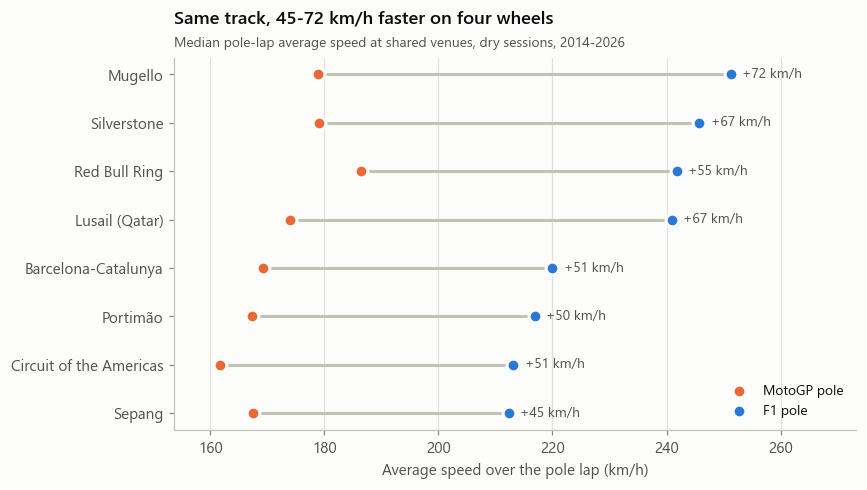

In [4]:
fig = plots.pole_speed_dumbbell(vc)
plots.save(fig, "pole_speed_dumbbell")
plt.show()

In [5]:
med = plots.venue_medians(vc)
med.style.format({"f1_kph": "{:.0f}", "mgp_kph": "{:.0f}", "ratio": "{:.3f}", "gap_s": "{:.1f}",
                  "same_layout": "{:.0%}"})

,f1_kph,mgp_kph,ratio,gap_s,seasons,same_layout
venue_name,,,,,,
Sepang,212,168,1.253,23.8,4,100%
Circuit of the Americas,213,162,1.309,28.5,11,100%
Portimão,217,167,1.280,21.6,2,0%
Barcelona-Catalunya,220,169,1.307,23.2,13,46%
Lusail (Qatar),241,174,1.384,30.7,4,25%
Red Bull Ring,242,186,1.322,20.3,12,58%
Silverstone,246,179,1.374,31.9,12,100%
Mugello,251,179,1.404,30.4,1,100%


## Where is the gap biggest?

Bikes give away the most on **fast, flowing circuits** such as Mugello, Silverstone and Lusail,
where an F1 car's downforce lets it carry far more speed through high-speed corners. The gap is
smallest at **slower, braking-heavy tracks** (Sepang, Portimão, Barcelona, COTA), where
acceleration and braking matter more than cornering grip.

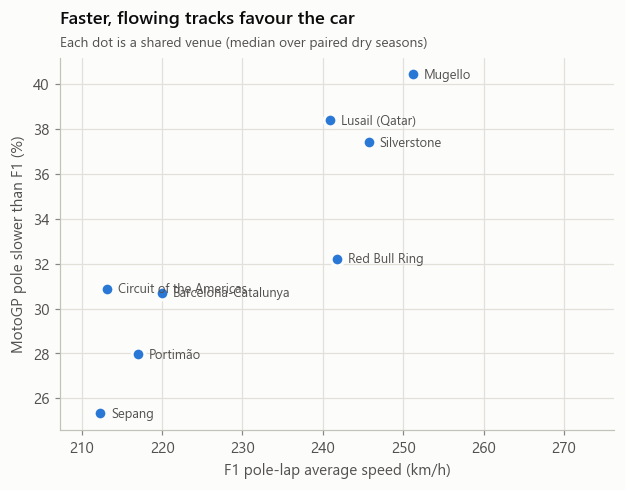

Spearman correlation between F1 pole speed and the MotoGP/F1 ratio across venues: 0.86 (n = 8 venues, so treat as indicative)


In [6]:
fig = plots.ratio_vs_speed(vc)
plots.save(fig, "ratio_vs_speed")
plt.show()
corr = med["f1_kph"].corr(med["ratio"], method="spearman")
print(f"Spearman correlation between F1 pole speed and the MotoGP/F1 ratio across venues: {corr:.2f}"
      f" (n = {len(med)} venues, so treat as indicative)")

## The gap over time

Because these are the same layouts, the trend shows how the rulebooks change the gap. F1's 2022
ground-effect cars and 2026 regulation reset both made F1 slower, while MotoGP bikes have kept
getting quicker (aero, ride-height devices).

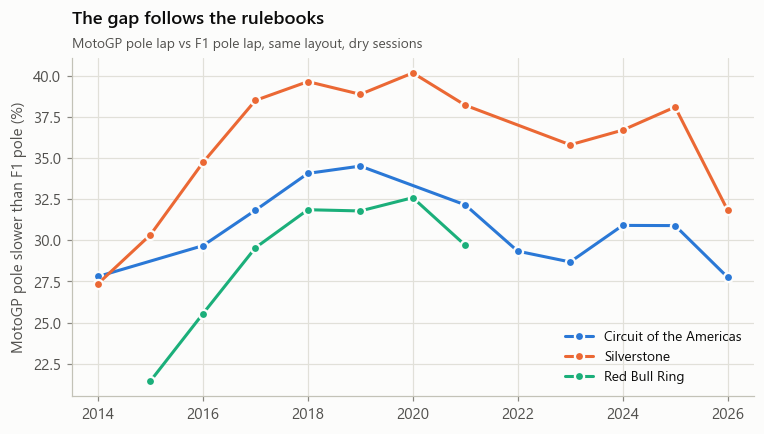

In [7]:
fig = plots.pole_ratio_trend(vc)
plots.save(fig, "pole_ratio_trend")
plt.show()

In [8]:
vc[vc["same_layout"]].pivot_table(index="f1_season", columns="venue_name", values="pole_ratio").round(3)

venue_name,Barcelona-Catalunya,Circuit of the Americas,Lusail (Qatar),Mugello,Red Bull Ring,Sepang,Silverstone
f1_season,,,,,,,
2014,NaN,1.278,NaN,NaN,NaN,NaN,1.274
2015,NaN,NaN,NaN,NaN,1.215,1.199,1.303
2016,1.263,1.297,NaN,NaN,1.255,1.282,1.347
2017,1.312,1.318,NaN,NaN,1.295,1.323,1.385
2018,NaN,1.341,NaN,NaN,1.319,NaN,1.396
2019,NaN,1.345,NaN,NaN,1.318,NaN,1.389
2020,NaN,NaN,NaN,1.404,1.326,NaN,1.402
2021,NaN,1.322,1.395,NaN,1.297,NaN,1.382
2022,NaN,1.293,NaN,NaN,NaN,NaN,NaN
